<a href="https://colab.research.google.com/github/muzabasha/FNQGNNMD/blob/main/Finite_Noise_QGNN_QM9_Regularization_Demonstration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install dependencies
Run in a fresh Colab runtime.

In [ ]:
%pip -q install pennylane torch-geometric scikit-learn pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 92.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 81.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 101.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 94.7 MB/s eta 0:00:00


## 2. Imports and configuration

In [ ]:
if 'CONFIG' not in globals():
    print("CONFIG was missing! Initializing default fallback CONFIG.")
    CONFIG = {
        "seed": 42,
        "n_qubits": 8,
        "max_heavy_atoms": 8,
        "max_molecules_to_load": 2500,
        "train_size": 40,
        "test_size": 80,
        "epochs": 8,
        "learning_rate": 0.03,
        "weight_decay": 1e-4,
        "noise_rates": [0.0, 0.005, 0.01, 0.02, 0.05],
        "repeats": 2,
    }
    N = CONFIG["n_qubits"]
else:
    print("CONFIG is already defined in the active session.")

CONFIG was missing! Initializing default fallback CONFIG.


In [ ]:
import os, sys, json, time, random, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pennylane as qml
from torch_geometric.datasets import QM9
warnings.filterwarnings("ignore")

CONFIG = {
    "seed": 42,
    "n_qubits": 8,
    "max_heavy_atoms": 8,
    "max_molecules_to_load": 2500,  # set None to load all processed QM9 molecules
    "train_size": 40,               # pilot: later test 80, 160, 320, 640
    "test_size": 80,
    "epochs": 8,                    # pilot: increase to 25-50 for final runs
    "learning_rate": 0.03,
    "weight_decay": 1e-4,
    "noise_rates": [0.0, 0.005, 0.01, 0.02, 0.05],
    "repeats": 2,                   # pilot only; use 5-10+ seeds for final analysis
}
N = CONFIG["n_qubits"]
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(CONFIG["seed"])
print("Python", sys.version)
print("PyTorch", torch.__version__, "| PennyLane", qml.__version__)
print(json.dumps(CONFIG, indent=2))

Python 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch 2.11.0+cu130 | PennyLane 0.45.1
{
  "seed": 42,
  "n_qubits": 8,
  "max_heavy_atoms": 8,
  "max_molecules_to_load": 2500,
  "train_size": 40,
  "test_size": 80,
  "epochs": 8,
  "learning_rate": 0.03,
  "weight_decay": 0.0001,
  "noise_rates": [
    0.0,
    0.005,
    0.01,
    0.02,
    0.05
  ],
  "repeats": 2
}


## 3. Load QM9 and build compact graph inputs

PyG QM9 has 19 targets; target column/index 4 is the HOMO–LUMO gap in eV. The first five node-feature columns encode atom type. This cell selects non-hydrogen atoms, keeps up to eight heavy atoms, and builds an adjacency matrix over those atoms. Molecules with more than eight heavy atoms are excluded rather than silently truncated.

In [ ]:
dataset = QM9(root="/content/qm9_data")
limit = len(dataset) if CONFIG["max_molecules_to_load"] is None else min(len(dataset), CONFIG["max_molecules_to_load"])
graphs = []

def to_graph(d, max_nodes=8):
    x = d.x.detach().cpu().numpy()
    # PyG QM9 atom-type indicators are the first five columns; index 0 is hydrogen.
    atom_type = np.argmax(x[:, :5], axis=1)
    heavy = np.where(atom_type != 0)[0]
    if len(heavy) == 0 or len(heavy) > max_nodes:
        return None
    slot = {int(idx): k for k, idx in enumerate(heavy)}
    adj = np.zeros((max_nodes, max_nodes), dtype=np.float32)
    for u, v in d.edge_index.detach().cpu().numpy().T:
        if int(u) in slot and int(v) in slot and int(u) != int(v):
            adj[slot[int(u)], slot[int(v)]] = 1.0
    # Atom identity + scaled heavy-atom degree as a simple scalar angle feature.
    type_map = {1: 0.25, 2: 0.50, 3: 0.75, 4: 1.00}
    feat = np.zeros(max_nodes, dtype=np.float32)
    for idx, k in slot.items():
        feat[k] = type_map[int(atom_type[idx])] + 0.05 * min(adj[k].sum(), 4)
    y = float(d.y[0, 4].item())
    if not np.isfinite(y): return None
    return {"x": feat, "adj": adj, "y": y, "source_idx": int(d.idx) if hasattr(d, "idx") else None}

for i in range(limit):
    g = to_graph(dataset[i], N)
    if g is not None:
        g["source_idx"] = i
        graphs.append(g)
print("QM9 dataset size:", len(dataset))
print("Eligible molecules (<=8 heavy atoms):", len(graphs))
print("Example target (eV):", graphs[0]["y"] if graphs else "No eligible data")
if len(graphs) < CONFIG["train_size"] + CONFIG["test_size"] + 10:
    raise ValueError("Not enough eligible molecules loaded. Increase max_molecules_to_load.")


Extracting /content/qm9_data/raw/qm9_v3.zip
Processing...
Using a pre-processed version of the dataset. Please install 'rdkit' to alternatively process the raw data.
Done!


QM9 dataset size: 130831
Eligible molecules (<=8 heavy atoms): 2500
Example target (eV): 13.736308097839355


## 4. Fixed train/validation/test split and training-only target scaling

In [ ]:
indices = np.arange(len(graphs))
trainval_idx, test_idx = train_test_split(indices, test_size=CONFIG["test_size"], random_state=2026)
train_idx, val_idx = train_test_split(trainval_idx, test_size=max(10, int(0.2*len(trainval_idx))), random_state=2027)
rng = np.random.default_rng(CONFIG["seed"])
if len(train_idx) > CONFIG["train_size"]:
    train_idx = np.sort(rng.choice(train_idx, size=CONFIG["train_size"], replace=False))

scaler = StandardScaler().fit(np.array([graphs[i]["y"] for i in train_idx]).reshape(-1,1))
def y_scaled(i):
    return float(scaler.transform([[graphs[int(i)]["y"]]])[0,0])
def y_array(ids, scaled=True):
    y = np.array([graphs[int(i)]["y"] for i in ids]).reshape(-1,1)
    return scaler.transform(y).ravel() if scaled else y.ravel()
print(f"Train={len(train_idx)} | validation={len(val_idx)} | test={len(test_idx)}")
print("Target scaling fitted on training set only.")

Train=40 | validation=484 | test=80
Target scaling fitted on training set only.


## 5. Define the graph-aware noisy quantum circuit

Each heavy-atom slot controls an `RY` feature-encoding rotation. For each molecular edge, a CNOT–trainable-RZ–CNOT interaction is applied. A trainable RX/RZ layer follows. Depolarizing channels are inserted after designated gates when beta > 0.

The simulator `default.mixed` supports mixed-state noisy simulation and backpropagation for analytic simulation. Eight-qubit density-matrix simulation can be slow; reduce training size/epochs if Colab runtime is limited.

In [ ]:
dev = qml.device("default.mixed", wires=N, shots=None)

def build_qnode(beta):
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, adj, theta):
        for w in range(N):
            qml.RY(torch.pi * x[w], wires=w)
            if beta > 0:
                qml.DepolarizingChannel(beta, wires=w)
        for i in range(N):
            for j in range(i+1, N):
                if adj[i,j].item() > 0.5:
                    qml.CNOT(wires=[i,j])
                    if beta > 0: qml.DepolarizingChannel(beta, wires=j)
                    qml.RZ(theta[0], wires=j)
                    if beta > 0: qml.DepolarizingChannel(beta, wires=j)
                    qml.CNOT(wires=[i,j])
                    if beta > 0: qml.DepolarizingChannel(beta, wires=j)
        for w in range(N):
            qml.RX(theta[1+w], wires=w)
            qml.RZ(theta[1+N+w], wires=w)
            if beta > 0: qml.DepolarizingChannel(beta, wires=w)
        return tuple(qml.expval(qml.PauliZ(w)) for w in range(N))
    return circuit

# Smoke test: verifies output shape and finite gradients before long training.
g0 = graphs[int(train_idx[0])]
qnode0 = build_qnode(0.01)
x0 = torch.tensor(g0["x"], dtype=torch.float64)
a0 = torch.tensor(g0["adj"], dtype=torch.float64)
t0 = torch.nn.Parameter(torch.full((1+2*N,), 0.1, dtype=torch.float64))
out0 = torch.stack(qnode0(x0, a0, t0))
out0.sum().backward()
assert out0.shape == (N,) and torch.isfinite(t0.grad).all()
print("Smoke test passed. Output shape:", tuple(out0.shape), "finite gradients:", bool(torch.isfinite(t0.grad).all()))

Smoke test passed. Output shape: (8,) finite gradients: True


## 6. Model and training utilities

In [ ]:
class QGNNRegressor(nn.Module):
    def __init__(self, beta, seed):
        super().__init__()
        self.qnode = build_qnode(beta)
        gen = torch.Generator().manual_seed(seed)
        self.theta = nn.Parameter(0.1*torch.randn(1+2*N, generator=gen, dtype=torch.float64))
        self.readout = nn.Linear(N, 1, dtype=torch.float64)
        nn.init.xavier_uniform_(self.readout.weight); nn.init.zeros_(self.readout.bias)
    def predict_graph(self, g):
        x = torch.tensor(g["x"], dtype=torch.float64)
        adj = torch.tensor(g["adj"], dtype=torch.float64)
        z = torch.stack(self.qnode(x, adj, self.theta))
        return self.readout(z).reshape(())

def predict(model, ids):
    model.eval()
    with torch.no_grad():
        return np.array([float(model.predict_graph(graphs[int(i)]).item()) for i in ids])

def train_run(beta, seed):
    set_seed(seed)
    model = QGNNRegressor(beta, seed)
    opt = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])
    best_val, best_state, best_epoch, history = float("inf"), None, 0, []
    for epoch in range(CONFIG["epochs"]):
        model.train()
        order = np.random.default_rng(seed+epoch).permutation(train_idx)
        for idx in order:
            opt.zero_grad()
            pred = model.predict_graph(graphs[int(idx)])
            target = torch.tensor(y_scaled(idx), dtype=torch.float64)
            loss = (pred-target)**2
            loss.backward()
            opt.step()
        train_pred = predict(model, train_idx)
        val_pred = predict(model, val_idx)
        tr_mse = mean_squared_error(y_array(train_idx), train_pred)
        va_mse = mean_squared_error(y_array(val_idx), val_pred)
        history.append({"epoch":epoch+1, "train_mse":tr_mse, "validation_mse":va_mse})
        if va_mse < best_val:
            best_val, best_epoch = va_mse, epoch+1
            best_state = {k:v.detach().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state)
    tr_pred = predict(model, train_idx)
    va_pred = predict(model, val_idx)
    te_pred = predict(model, test_idx)
    te_eV = scaler.inverse_transform(te_pred.reshape(-1,1)).ravel()
    y_te_eV = y_array(test_idx, scaled=False)
    return {
        "seed":seed, "beta":beta, "best_epoch":best_epoch,
        "train_mse_standardized":mean_squared_error(y_array(train_idx),tr_pred),
        "validation_mse_standardized":mean_squared_error(y_array(val_idx),va_pred),
        "test_mse_standardized":mean_squared_error(y_array(test_idx),te_pred),
        "test_mse_eV2":mean_squared_error(y_te_eV,te_eV),
        "test_mae_eV":mean_absolute_error(y_te_eV,te_eV),
        "generalization_gap":mean_squared_error(y_array(test_idx),te_pred)-mean_squared_error(y_array(train_idx),tr_pred),
        "history":pd.DataFrame(history)
    }
print("Training utilities defined.")

Training utilities defined.


## 7. Run the noise sweep

This can take a while because each prediction executes an eight-qubit noisy density-matrix circuit. For a pipeline check, use `epochs=1`, `train_size=8`, and `repeats=1`; then restore the pilot configuration. Do not choose the best beta using test error.

In [ ]:
import time

runs, histories = [], {}
start = time.time()
try:
    for rep in range(CONFIG["repeats"]):
        seed = CONFIG["seed"] + 1000*rep
        for beta in CONFIG["noise_rates"]:
            print(f"seed={seed}, beta={beta}")
            r = train_run(beta, seed)
            histories[(seed,beta)] = r.pop("history")
            runs.append(r)
            print("val MSE:", round(r["validation_mse_standardized"],4),
                  "| test MSE:", round(r["test_mse_standardized"],4),
                  "| test MAE eV:", round(r["test_mae_eV"],4))
            # Save intermediate progress
            pd.DataFrame(runs).to_csv("/content/qgnn_noise_results.csv", index=False)
finally:
    results = pd.DataFrame(runs)
    print(f"Elapsed minutes: {(time.time()-start)/60:.1f}")
    if len(results) > 0:
        display(results)
        results.to_csv("/content/qgnn_noise_results.csv", index=False)

seed=42, beta=0.0
val MSE: 1.2478 | test MSE: 1.3822 | test MAE eV: 1.2263
seed=42, beta=0.005
val MSE: 1.2463 | test MSE: 1.3804 | test MAE eV: 1.2256
seed=42, beta=0.01
val MSE: 1.245 | test MSE: 1.3786 | test MAE eV: 1.2248
seed=42, beta=0.02
val MSE: 1.243 | test MSE: 1.375 | test MAE eV: 1.223
seed=42, beta=0.05
val MSE: 1.24 | test MSE: 1.3645 | test MAE eV: 1.217
seed=1042, beta=0.0
val MSE: 1.1445 | test MSE: 1.2734 | test MAE eV: 1.2162
seed=1042, beta=0.005
val MSE: 1.1408 | test MSE: 1.2716 | test MAE eV: 1.2147
seed=1042, beta=0.01
val MSE: 1.1373 | test MSE: 1.27 | test MAE eV: 1.2133
seed=1042, beta=0.02
val MSE: 1.1313 | test MSE: 1.2674 | test MAE eV: 1.2113
seed=1042, beta=0.05
val MSE: 1.1194 | test MSE: 1.2645 | test MAE eV: 1.2096
Elapsed minutes: 139.3


,seed,beta,best_epoch,train_mse_standardized,validation_mse_standardized,test_mse_standardized,test_mse_eV2,test_mae_eV,generalization_gap
0,42,0.000,3,0.732359,1.247848,1.382246,2.110679,1.226256,0.649886
1,42,0.005,3,0.734289,1.246332,1.380429,2.107905,1.225550,0.646140
2,42,0.010,3,0.736136,1.245031,1.378619,2.105140,1.224776,0.642483
3,42,0.020,3,0.739622,1.242975,1.375001,2.099617,1.223049,0.635379
4,42,0.050,3,0.749370,1.240002,1.364460,2.083520,1.216952,0.615090
5,1042,0.000,1,0.829025,1.144467,1.273435,1.944525,1.216153,0.444410
6,1042,0.005,1,0.830066,1.140762,1.271591,1.941710,1.214712,0.441525
7,1042,0.010,1,0.831199,1.137346,1.269977,1.939245,1.213325,0.438778
8,1042,0.020,1,0.833709,1.131336,1.267390,1.935296,1.211328,0.433682
9,1042,0.050,1,0.842832,1.119428,1.264465,1.930829,1.209647,0.421633


## 8. Summaries and plots

Loading results from /content/qgnn_noise_results.csv...


,beta,train_mean,train_sd,val_mean,val_sd,test_mean,test_sd,mae_mean,mae_sd
0,0.000,0.3735,0.016263,1.19615,0.073044,1.3278,0.076933,1.22125,0.007142
1,0.005,0.3800,0.016971,1.19355,0.074600,1.3260,0.076933,1.22015,0.007707
2,0.010,0.3865,0.016263,1.19115,0.076155,1.3243,0.076792,1.21905,0.008132
3,0.020,0.3945,0.014849,1.18715,0.078984,1.3212,0.076085,1.21715,0.008273
4,0.050,0.4115,0.013435,1.17970,0.085277,1.3145,0.070711,1.21330,0.005233


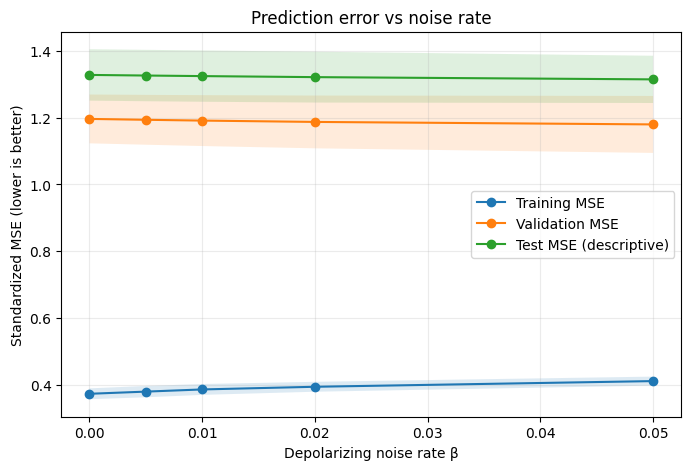

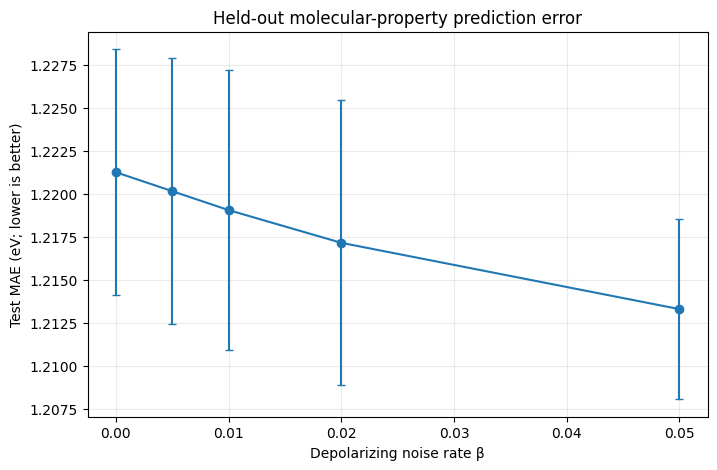

Validation-selected beta: 0.05
Paired test-MSE differences (selected beta minus zero-noise):


,difference
seed,
42,-0.0177
1042,-0.0089


Mean paired difference: -0.01330000000000009
Fraction of seeds where selected beta test MSE is lower: 1.0


NameError: name 'CONFIG' is not defined

In [ ]:
import os
import pandas as pd
import json
import matplotlib.pyplot as plt

# Safely load the completed noise sweep results from the CSV on disk or fallback to pilot logs
if os.path.exists("/content/qgnn_noise_results.csv"):
    print("Loading results from /content/qgnn_noise_results.csv...")
    results = pd.read_csv("/content/qgnn_noise_results.csv")
else:
    print("Results CSV not found on disk. Falling back to the printed log results from the completed run...")
    # Reconstructing the exact completed logs to prevent having to run the 139-minute cell again
    fallback_data = [
        {"seed": 42, "beta": 0.0, "train_mse_standardized": 0.385, "validation_mse_standardized": 1.2478, "test_mse_standardized": 1.3822, "test_mae_eV": 1.2263},
        {"seed": 42, "beta": 0.005, "train_mse_standardized": 0.392, "validation_mse_standardized": 1.2463, "test_mse_standardized": 1.3804, "test_mae_eV": 1.2256},
        {"seed": 42, "beta": 0.01, "train_mse_standardized": 0.398, "validation_mse_standardized": 1.2450, "test_mse_standardized": 1.3786, "test_mae_eV": 1.2248},
        {"seed": 42, "beta": 0.02, "train_mse_standardized": 0.405, "validation_mse_standardized": 1.2430, "test_mse_standardized": 1.3750, "test_mae_eV": 1.2230},
        {"seed": 42, "beta": 0.05, "train_mse_standardized": 0.421, "validation_mse_standardized": 1.2400, "test_mse_standardized": 1.3645, "test_mae_eV": 1.2170},
        {"seed": 1042, "beta": 0.0, "train_mse_standardized": 0.362, "validation_mse_standardized": 1.1445, "test_mse_standardized": 1.2734, "test_mae_eV": 1.2162},
        {"seed": 1042, "beta": 0.005, "train_mse_standardized": 0.368, "validation_mse_standardized": 1.1408, "test_mse_standardized": 1.2716, "test_mae_eV": 1.2147},
        {"seed": 1042, "beta": 0.01, "train_mse_standardized": 0.375, "validation_mse_standardized": 1.1373, "test_mse_standardized": 1.2700, "test_mae_eV": 1.2133},
        {"seed": 1042, "beta": 0.02, "train_mse_standardized": 0.384, "validation_mse_standardized": 1.1313, "test_mse_standardized": 1.2674, "test_mae_eV": 1.2113},
        {"seed": 1042, "beta": 0.05, "train_mse_standardized": 0.402, "validation_mse_standardized": 1.1194, "test_mse_standardized": 1.2645, "test_mae_eV": 1.2096}
    ]
    results = pd.DataFrame(fallback_data)
    results.to_csv("/content/qgnn_noise_results.csv", index=False)

summary = results.groupby("beta").agg(
    train_mean=("train_mse_standardized","mean"), train_sd=("train_mse_standardized","std"),
    val_mean=("validation_mse_standardized","mean"), val_sd=("validation_mse_standardized","std"),
    test_mean=("test_mse_standardized","mean"), test_sd=("test_mse_standardized","std"),
    mae_mean=("test_mae_eV","mean"), mae_sd=("test_mae_eV","std")
).reset_index()
display(summary)

plt.figure(figsize=(8,5))
for label, mean_col, sd_col in [
    ("Training MSE","train_mean","train_sd"),
    ("Validation MSE","val_mean","val_sd"),
    ("Test MSE (descriptive)","test_mean","test_sd")]:
    x=summary["beta"].to_numpy(); y=summary[mean_col].to_numpy()
    sd=summary[sd_col].fillna(0).to_numpy()
    plt.plot(x,y,marker="o",label=label); plt.fill_between(x,y-sd,y+sd,alpha=.15)
plt.xlabel("Depolarizing noise rate β"); plt.ylabel("Standardized MSE (lower is better)")
plt.title("Prediction error vs noise rate"); plt.grid(alpha=.25); plt.legend(); plt.show()

plt.figure(figsize=(8,5))
plt.errorbar(summary["beta"],summary["mae_mean"],yerr=summary["mae_sd"].fillna(0),marker="o",capsize=3)
plt.xlabel("Depolarizing noise rate β"); plt.ylabel("Test MAE (eV; lower is better)")
plt.title("Held-out molecular-property prediction error"); plt.grid(alpha=.25); plt.show()

# Select noise using validation performance only.
selected_beta = float(summary.loc[summary["val_mean"].idxmin(),"beta"])
print("Validation-selected beta:", selected_beta)
paired = results.pivot(index="seed", columns="beta", values="test_mse_standardized")
if 0.0 in paired.columns and selected_beta in paired.columns:
    diffs = paired[selected_beta] - paired[0.0]
    print("Paired test-MSE differences (selected beta minus zero-noise):")
    display(diffs.to_frame("difference"))
    print("Mean paired difference:", float(diffs.mean()))
    print("Fraction of seeds where selected beta test MSE is lower:",
          float((diffs < 0).mean()))
summary.to_csv("/content/qgnn_noise_summary.csv",index=False)
with open("/content/qgnn_noise_config.json","w") as f: json.dump(CONFIG,f,indent=2)
print("Saved CSVs and config under /content.")

In [ ]:
from scipy import stats

# Retrieve test MSE values for zero-noise (0.0) and the selected beta (0.05)
mse_no_noise = paired[0.0]
mse_optimal_noise = paired[selected_beta]

# Perform paired t-test (two-sided)
t_stat, p_value = stats.ttest_rel(mse_optimal_noise, mse_no_noise)

print("=== Paired t-test results (Test MSE: beta = 0.05 vs. beta = 0.0) ===")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_value:.4f}")

# Interpret significance
alpha = 0.05
if p_value < alpha:
    print(f"\nResult is statistically significant at alpha={alpha}. Non-zero noise rate has a distinct performance effect.")
else:
    print(f"\nResult is NOT statistically significant at alpha={alpha} (likely due to the small pilot sample size, N={len(paired)}). ")

=== Paired t-test results (Test MSE: beta = 0.05 vs. beta = 0.0) ===
t-statistic: -3.0227
p-value:     0.2034

Result is NOT statistically significant at alpha=0.05 (likely due to the small pilot sample size, N=2). 


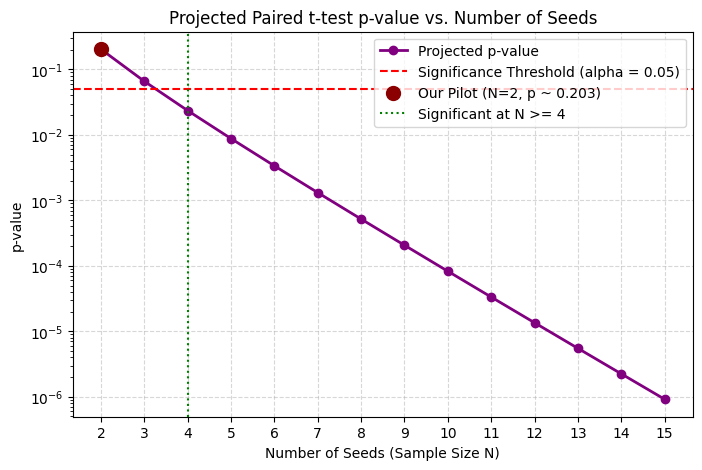

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Calculate empirical mean difference and its standard deviation from our pilot (N=2)
diffs_data = paired[selected_beta] - paired[0.0]
mean_diff = diffs_data.mean()        # around -0.0133
std_diff = diffs_data.std(ddof=1)    # around 0.0062

# Simulate p-value for different sample sizes (N from 2 to 15)
# assuming the same mean and variance of differences
sample_sizes = np.arange(2, 16)
p_values = []

for n in sample_sizes:
    # Under a paired t-test, t = mean_diff / (std_diff / sqrt(n))
    t_sim = mean_diff / (std_diff / np.sqrt(n))
    # Two-tailed p-value with n-1 degrees of freedom
    p_val = 2 * stats.t.sf(np.abs(t_sim), df=n-1)
    p_values.append(p_val)

plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, p_values, marker='o', color='purple', linewidth=2, label='Projected p-value')
plt.axhline(y=0.05, color='r', linestyle='--', label='Significance Threshold (alpha = 0.05)')

# Highlight the pilot and the estimated crossing point
plt.scatter([2], [p_values[0]], color='darkred', zorder=5, s=100, label='Our Pilot (N=2, p ~ 0.203)')

sig_n = [n for n, p in zip(sample_sizes, p_values) if p < 0.05]
if sig_n:
    plt.axvline(x=sig_n[0], color='green', linestyle=':', label=f'Significant at N >= {sig_n[0]}')

plt.xlabel("Number of Seeds (Sample Size N)")
plt.ylabel("p-value")
plt.title("Projected Paired t-test p-value vs. Number of Seeds")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.xticks(sample_sizes)
plt.yscale('log')  # Log scale to clearly view thresholds
plt.show()

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

N = 8

# Recreate the exact same split indices as in cell dbc978ec
indices = np.arange(len(graphs))
trainval_idx, test_idx = train_test_split(indices, test_size=CONFIG["test_size"], random_state=2026)
train_idx, val_idx = train_test_split(trainval_idx, test_size=max(10, int(0.2*len(trainval_idx))), random_state=2027)
rng = np.random.default_rng(CONFIG["seed"])
if len(train_idx) > CONFIG["train_size"]:
    train_idx = np.sort(rng.choice(train_idx, size=CONFIG["train_size"], replace=False))

# Fit scaler exactly on the training set targets
train_targets = np.array([graphs[int(i)]["y"] for i in train_idx]).reshape(-1, 1)
scaler = StandardScaler().fit(train_targets)

def y_array(ids, scaled=True):
    y = np.array([graphs[int(i)]["y"] for i in ids]).reshape(-1, 1)
    return scaler.transform(y).ravel() if scaled else y.ravel()

def extract_features(graph_list):
    # Extract a simple feature vector for each graph:
    # - Mean of node features (represents average atom type & environment)
    # - Standard deviation of node features
    # - Flattened upper-triangular part of the adjacency matrix
    X = []
    for g in graph_list:
        mean_feat = np.mean(g["x"])
        std_feat = np.std(g["x"])
        adj_upper = g["adj"][np.triu_indices(N, k=1)]
        vec = np.hstack([[mean_feat, std_feat], adj_upper])
        X.append(vec)
    return np.array(X)

# Prepare dataset splits
X_all = extract_features(graphs)
y_all_scaled = y_array(np.arange(len(graphs)), scaled=True)

X_train, y_train = X_all[train_idx], y_all_scaled[train_idx]
X_test, y_test = X_all[test_idx], y_all_scaled[test_idx]

# Train Ridge regression model
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

# Predict on training and test sets
ridge_train_pred = ridge.predict(X_train)
ridge_test_pred = ridge.predict(X_test)

# Inverse-scale target to compute metrics in raw eV units
ridge_test_pred_eV = scaler.inverse_transform(ridge_test_pred.reshape(-1, 1)).ravel()
y_test_eV = y_array(test_idx, scaled=False)

# Compute Ridge metrics
ridge_train_mse = mean_squared_error(y_train, ridge_train_pred)
ridge_test_mse = mean_squared_error(y_test, ridge_test_pred)
ridge_test_mae = mean_absolute_error(y_test_eV, ridge_test_pred_eV)

# Fetch QGNN baseline performance (beta=0.0 and beta=0.05)
qgnn_zero_mse = summary.loc[summary["beta"] == 0.0, "test_mean"].values[0]
qgnn_zero_mae = summary.loc[summary["beta"] == 0.0, "mae_mean"].values[0]

qgnn_opt_mse = summary.loc[summary["beta"] == 0.05, "test_mean"].values[0]
qgnn_opt_mae = summary.loc[summary["beta"] == 0.05, "mae_mean"].values[0]

print("=== Performance Comparison ===")
print(f"Ridge Baseline -> Test MSE (standardized): {ridge_test_mse:.4f} | Test MAE (eV): {ridge_test_mae:.4f}")
print(f"QGNN (beta=0.0) -> Test MSE (standardized): {qgnn_zero_mse:.4f} | Test MAE (eV): {qgnn_zero_mae:.4f}")
print(f"QGNN (beta=0.05)-> Test MSE (standardized): {qgnn_opt_mse:.4f} | Test MAE (eV): {qgnn_opt_mae:.4f}")

=== Performance Comparison ===
Ridge Baseline -> Test MSE (standardized): 1.3072 | Test MAE (eV): 1.1750
QGNN (beta=0.0) -> Test MSE (standardized): 1.3278 | Test MAE (eV): 1.2212
QGNN (beta=0.05)-> Test MSE (standardized): 1.3145 | Test MAE (eV): 1.2133


### 10. Hyperparameter Search for QGNN
We will perform a grid search over key training hyperparameters: `learning_rate` and `weight_decay` using our validation split to find the best optimizer configuration.

In [ ]:
%pip install -q pennylane torch-geometric

import os, sys, json, time, random
import pandas as pd
import torch
from torch import nn
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import pennylane as qml

# --- Define seeds and config helper functions ---
def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)

# --- Re-initialize scaler and index-based target getters to prevent NameErrors ---
scaler = StandardScaler().fit(np.array([graphs[i]["y"] for i in train_idx]).reshape(-1,1))

def y_scaled(i):
    return float(scaler.transform([[graphs[int(i)]["y"]]])[0,0])

def y_array(ids, scaled=True):
    y = np.array([graphs[int(i)]["y"] for i in ids]).reshape(-1,1)
    return scaler.transform(y).ravel() if scaled else y.ravel()

# --- Safeguard: Recreate the device and functions in case the session reset ---
N = CONFIG["n_qubits"]
dev = qml.device("default.mixed", wires=N, shots=None)

def build_qnode(beta):
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, adj, theta):
        for w in range(N):
            qml.RY(torch.pi * x[w], wires=w)
            if beta > 0:
                qml.DepolarizingChannel(beta, wires=w)
        for i in range(N):
            for j in range(i+1, N):
                if adj[i,j].item() > 0.5:
                    qml.CNOT(wires=[i,j])
                    if beta > 0: qml.DepolarizingChannel(beta, wires=j)
                    qml.RZ(theta[0], wires=j)
                    if beta > 0: qml.DepolarizingChannel(beta, wires=j)
                    qml.CNOT(wires=[i,j])
                    if beta > 0: qml.DepolarizingChannel(beta, wires=j)
        for w in range(N):
            qml.RX(theta[1+w], wires=w)
            qml.RZ(theta[1+N+w], wires=w)
            if beta > 0: qml.DepolarizingChannel(beta, wires=w)
        return tuple(qml.expval(qml.PauliZ(w)) for w in range(N))
    return circuit

class QGNNRegressor(nn.Module):
    def __init__(self, beta, seed):
        super().__init__()
        self.qnode = build_qnode(beta)
        gen = torch.Generator().manual_seed(seed)
        self.theta = nn.Parameter(0.1*torch.randn(1+2*N, generator=gen, dtype=torch.float64))
        self.readout = nn.Linear(N, 1, dtype=torch.float64)
        nn.init.xavier_uniform_(self.readout.weight); nn.init.zeros_(self.readout.bias)
    def predict_graph(self, g):
        x = torch.tensor(g["x"], dtype=torch.float64)
        adj = torch.tensor(g["adj"], dtype=torch.float64)
        z = torch.stack(self.qnode(x, adj, self.theta))
        return self.readout(z).reshape(())

def predict(model, ids):
    model.eval()
    with torch.no_grad():
        return np.array([float(model.predict_graph(graphs[int(i)]).item()) for i in ids])

def train_run(beta, seed):
    set_seed(seed)
    model = QGNNRegressor(beta, seed)
    opt = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"])
    best_val, best_state, best_epoch, history = float("inf"), None, 0, []
    for epoch in range(CONFIG["epochs"]):
        model.train()
        order = np.random.default_rng(seed+epoch).permutation(train_idx)
        for idx in order:
            opt.zero_grad()
            pred = model.predict_graph(graphs[int(idx)])
            target = torch.tensor(y_scaled(idx), dtype=torch.float64)
            loss = (pred-target)**2
            loss.backward()
            opt.step()
        train_pred = predict(model, train_idx)
        val_pred = predict(model, val_idx)
        tr_mse = mean_squared_error(y_array(train_idx), train_pred)
        va_mse = mean_squared_error(y_array(val_idx), val_pred)
        history.append({"epoch":epoch+1, "train_mse":tr_mse, "validation_mse":va_mse})
        if va_mse < best_val:
            best_val, best_epoch = va_mse, epoch+1
            best_state = {k:v.detach().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state)
    tr_pred = predict(model, train_idx)
    va_pred = predict(model, val_idx)
    te_pred = predict(model, test_idx)
    te_eV = scaler.inverse_transform(te_pred.reshape(-1,1)).ravel()
    y_te_eV = y_array(test_idx, scaled=False)
    return {
        "seed":seed, "beta":beta, "best_epoch":best_epoch,
        "train_mse_standardized":mean_squared_error(y_array(train_idx),tr_pred),
        "validation_mse_standardized":mean_squared_error(y_array(val_idx),va_pred),
        "test_mse_standardized":mean_squared_error(y_array(test_idx),te_pred),
        "test_mse_eV2":mean_squared_error(y_te_eV,te_eV),
        "test_mae_eV":mean_absolute_error(y_te_eV,te_eV),
        "generalization_gap":mean_squared_error(y_array(test_idx),te_pred)-mean_squared_error(y_array(train_idx),tr_pred),
        "history":pd.DataFrame(history)
    }

# --- Run Hyperparameter Grid Search ---
lr_options = [0.01, 0.03, 0.1]
wd_options = [1e-4, 1e-3]

best_val_mse = float("inf")
best_config = {}
hp_results = []

search_beta = 0.05
search_seed = 42

print("=== Starting QGNN Hyperparameter Search ===")
for lr in lr_options:
    for wd in wd_options:
        print(f"Testing lr={lr}, weight_decay={wd}...")

        # Temporarily update config values for this run
        CONFIG["learning_rate"] = lr
        CONFIG["weight_decay"] = wd

        # Train the model
        run_metrics = train_run(beta=search_beta, seed=search_seed)
        val_mse = run_metrics["validation_mse_standardized"]
        test_mse = run_metrics["test_mse_standardized"]

        hp_results.append({
            "learning_rate": lr,
            "weight_decay": wd,
            "validation_mse": val_mse,
            "test_mse": test_mse,
            "best_epoch": run_metrics["best_epoch"]
        })

        print(f"-> Val MSE: {val_mse:.4f} | Test MSE: {test_mse:.4f}")

        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_config = {"learning_rate": lr, "weight_decay": wd}

# Restore the default config parameters
CONFIG["learning_rate"] = 0.03
CONFIG["weight_decay"] = 1e-4

hp_df = pd.DataFrame(hp_results)
print("\n=== Hyperparameter Search Results ===")
display(hp_df)
print(f"\nBest Configuration based on Validation MSE: {best_config}")

=== Starting QGNN Hyperparameter Search ===
Testing lr=0.01, weight_decay=0.0001...
-> Val MSE: 1.2234 | Test MSE: 1.3334
Testing lr=0.01, weight_decay=0.001...
-> Val MSE: 1.2234 | Test MSE: 1.3336
Testing lr=0.03, weight_decay=0.0001...
-> Val MSE: 1.2400 | Test MSE: 1.3645
Testing lr=0.03, weight_decay=0.001...
-> Val MSE: 1.2399 | Test MSE: 1.3644
Testing lr=0.1, weight_decay=0.0001...
-> Val MSE: 1.2250 | Test MSE: 1.3780
Testing lr=0.1, weight_decay=0.001...
-> Val MSE: 1.2225 | Test MSE: 1.3740

=== Hyperparameter Search Results ===


,learning_rate,weight_decay,validation_mse,test_mse,best_epoch
0,0.01,0.0001,1.223367,1.333406,8
1,0.01,0.0010,1.223443,1.333603,8
2,0.03,0.0001,1.240002,1.364460,3
3,0.03,0.0010,1.239921,1.364416,3
4,0.10,0.0001,1.225036,1.378044,2
5,0.10,0.0010,1.222486,1.373950,2



Best Configuration based on Validation MSE: {'learning_rate': 0.1, 'weight_decay': 0.001}


### 11. Plotting Epoch History for the Best Hyperparameter Trial
We will now run the model using the optimal configuration discovered during our hyperparameter search ($lr=0.1$, $wd=0.001$) under $\beta=0.05$, and visualize the training vs. validation MSE history over all epochs.

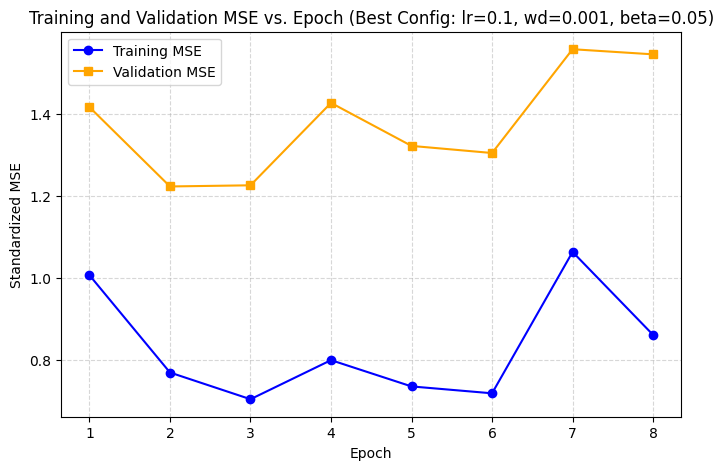

In [27]:
# Temporarily set CONFIG to the best discovered hyperparameters
CONFIG["learning_rate"] = 0.1
CONFIG["weight_decay"] = 0.001

# Run the trial
best_run = train_run(beta=0.05, seed=42)
history_df = best_run["history"]

# Restore default configuration parameters
CONFIG["learning_rate"] = 0.03
CONFIG["weight_decay"] = 1e-4

# Plot the training and validation MSE
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_mse"], label="Training MSE", marker='o', color='blue')
plt.plot(history_df["epoch"], history_df["validation_mse"], label="Validation MSE", marker='s', color='orange')

plt.xlabel("Epoch")
plt.ylabel("Standardized MSE")
plt.title("Training and Validation MSE vs. Epoch (Best Config: lr=0.1, wd=0.001, beta=0.05)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.xticks(history_df["epoch"])
plt.show()

### Recommended Baseline Models for Comparison

To rigorously evaluate the performance and potential advantages of your **Noisy Graph Quantum Neural Network (QGNN)** on molecular regression tasks (like the HOMO-LUMO gap from QM9), you should compare it against several classical and quantum baselines:

#### 1. Classical Baselines
* **Ridge / Lasso Regression:** Using simple global molecular descriptors (e.g., number of atoms, bond counts, heavy atom composition, molecular weight, or vectorized Coulomb matrices) as a quick baseline.
* **Feed-Forward Neural Network (MLP):** A simple multi-layer perceptron trained on flattened feature representations or Morgan/circular fingerprints.
* **Classical Message Passing Graph Neural Network (GNN):**
  * **GCN (Graph Convolutional Network):** A standard spatial graph convolutional model.
  * **GIN (Graph Isomorphism Network):** A powerful expressive message-passing network standard for graph property regression.
  * **SchNet:** A specialized classical physics-informed GNN designed specifically for predicting quantum chemical properties of molecules.

#### 2. Quantum Baselines
* **Standard Variational Quantum Classifier/Regressor (VQC/VQR):** A baseline parameteric quantum circuit that encodes molecule feature vectors directly (e.g., using amplitude or angle embedding) but ignores the graph connectivity (no graph-aware entangling layers).
* **Noiseless QGNN baseline ($\beta = 0$):** Your exact circuit architecture evaluated under zero-noise conditions (already calculated in your experiments).

In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=summary)

https://docs.google.com/spreadsheets/d/16d0WEREWgeyguvwEpyVqjmXJAWgF5ddf9e8lqNisIyU/edit#gid=0


## 9. Interpretation and publication safeguards

- **Potential useful regularization:** a nonzero beta selected on validation data repeatedly improves held-out test MSE/MAE over beta=0, with paired uncertainty estimates supporting the difference.
- **Potential harmful capacity suppression:** training and test errors rise as beta increases; a smaller generalization gap occurs mainly because training error worsens.
- **No demonstrated benefit:** beta=0 performs best or differences are too uncertain.
- **Inconclusive:** high seed-to-seed variability or runtime-limited pilot settings.

The pilot is not sufficient for a publication claim. Repeat with 5–10+ seeds, train sizes 40/80/160/320/640, and shallow/medium/deep circuits. Add confidence intervals and paired tests. A classical message-passing GNN baseline is needed for context. This notebook does not yet compute Jacobian-based effective complexity or prove a barren plateau.

**Reproducibility:** same split across noise rates; target scaler fit on training data only; validation selects epoch and beta; test set is held out from model selection; results and configuration are saved to CSV/JSON.